Number of images: 60000
Image shape: torch.Size([1, 28, 28])
Digit label: 4
Minimum pixel value: 0.0
Maximum pixel value: 1.0


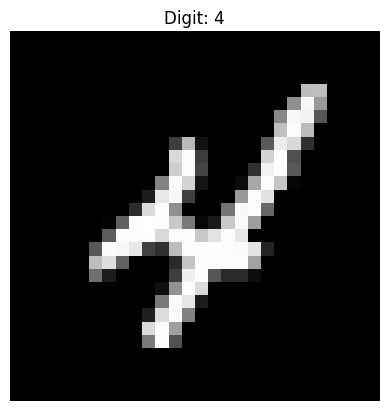

In [4]:
import torch
import matplotlib.pyplot as plt
from torchvision import datasets, transforms

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

print("Number of images:", len(train_dataset))

image, label = train_dataset[9]

print("Image shape:", image.shape)
print("Digit label:", label)
print("Minimum pixel value:", image.min().item())
print("Maximum pixel value:", image.max().item())

plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Digit: {label}")
plt.axis("off")
plt.show()

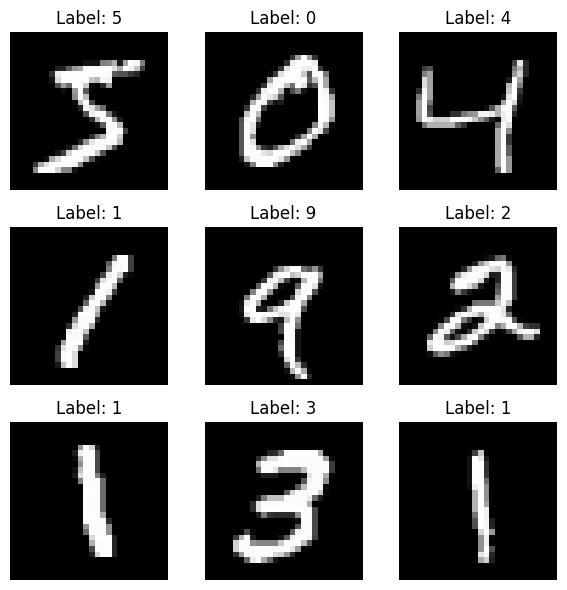

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(6, 6))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]

    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
image, label = train_dataset[0]

mean_brightness = image.mean().item()

print("Label:", label)
print("Mean pixel brightness:", mean_brightness)

Label: 5
Mean pixel brightness: 0.1376800686120987


In [7]:
image, label = train_dataset[0]

x = image.view(-1)

print("Original shape:", image.shape)
print("Flattened shape:", x.shape)
print("Label:", label)

Original shape: torch.Size([1, 28, 28])
Flattened shape: torch.Size([784])
Label: 5


In [8]:
import torch
import torch.nn as nn

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Linear(64, 16)
        )

        self.decoder = nn.Sequential(
            nn.Linear(16, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        reconstructed = self.decoder(z)
        return reconstructed

model = Autoencoder()

print(model)

Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=16, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=16, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


In [9]:
image, label = train_dataset[0]

x = image.view(1, 784)

with torch.no_grad():
    z = model.encoder(x)
    output = model(x)

print("Input shape:", x.shape)
print("Latent shape:", z.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([1, 784])
Latent shape: torch.Size([1, 16])
Output shape: torch.Size([1, 784])


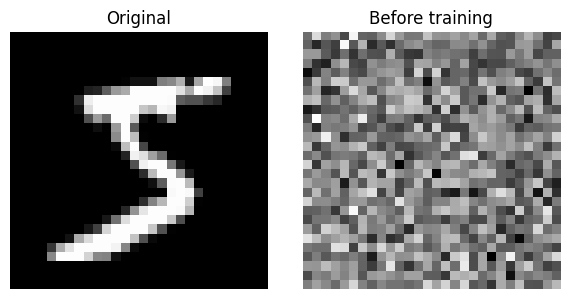

In [10]:
with torch.no_grad():
    reconstructed = model(image.view(1, 784))

reconstructed_image = reconstructed.view(28, 28)

fig, axes = plt.subplots(1, 2, figsize=(6, 3))

axes[0].imshow(image.squeeze(), cmap="gray")
axes[0].set_title("Original")

axes[1].imshow(reconstructed_image.numpy(), cmap="gray")
axes[1].set_title("Before training")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [11]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

print("Number of batches:", len(train_loader))

Number of batches: 469


In [14]:
import torch.nn as nn

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [15]:
epochs = 5

for epoch in range(epochs):
    model.train()
    total_loss = 0.0

    for images, labels in train_loader:
        # Flatten each image from (1, 28, 28) to 784 values
        images = images.view(images.size(0), 784)

        # 1. Reset gradients from the previous batch
        optimizer.zero_grad()

        # 2. Forward pass: reconstruct the images
        reconstructed = model(images)

        # 3. Calculate reconstruction error
        loss = criterion(reconstructed, images)

        # 4. Backpropagation: calculate gradients
        loss.backward()

        # 5. Update the model's weights
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    average_loss = total_loss / len(train_dataset)

    print(
        f"Epoch {epoch + 1}/{epochs} "
        f"| Reconstruction Loss: {average_loss:.5f}"
    )

Epoch 1/5 | Reconstruction Loss: 0.05453
Epoch 2/5 | Reconstruction Loss: 0.02755
Epoch 3/5 | Reconstruction Loss: 0.02254
Epoch 4/5 | Reconstruction Loss: 0.01990
Epoch 5/5 | Reconstruction Loss: 0.01775


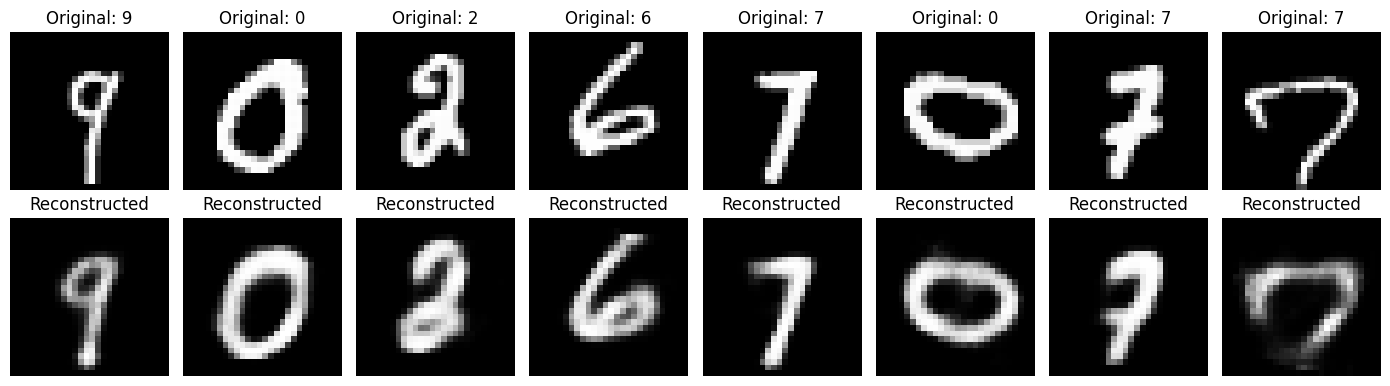

In [16]:
model.eval()

images, labels = next(iter(train_loader))
images = images[:8]

with torch.no_grad():
    reconstructed = model(images.view(-1, 784))

reconstructed = reconstructed.view(-1, 1, 28, 28)

fig, axes = plt.subplots(2, 8, figsize=(14, 4))

for i in range(8):
    axes[0, i].imshow(images[i].squeeze(), cmap="gray")
    axes[0, i].set_title(f"Original: {labels[i].item()}")

    axes[1, i].imshow(reconstructed[i].squeeze(), cmap="gray")
    axes[1, i].set_title("Reconstructed")

    axes[0, i].axis("off")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

**Evaluate on Unseen Data**

The training loss measures performance on images used during learning. We also need to evaluate the model on a separate test set to see how well it reconstructs images it did not train on.

We will calculate the mean squared error across all test pixels. A lower value means lower average squared pixel error, although it does not always mean that the images look perceptually better.

In [17]:
# Load the separate MNIST test split.
# These 10,000 images were not used to update the model's weights.

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transforms.ToTensor()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

# Evaluation mode disables training-specific behavior.
model.eval()
total_squared_error = 0.0
total_pixels = 0

# Gradients are unnecessary during evaluation.
with torch.no_grad():
    for images, labels in test_loader:
        images = images.view(images.size(0), 784)

        # Reconstruct the unseen images.
        reconstructed = model(images)

        # Sum squared pixel errors for this batch.
        total_squared_error += (
            (reconstructed - images) ** 2
        ).sum().item()

        total_pixels += images.numel()

test_mse = total_squared_error / total_pixels

print(f"Test MSE: {test_mse:.6f}")

Test MSE: 0.016414


**Where Does the Autoencoder Make Mistakes?**

Visual comparisons can reveal whether the model preserves digit shape. An error map highlights pixels where the reconstruction differs from the original. Bright error regions indicate larger absolute pixel differences.

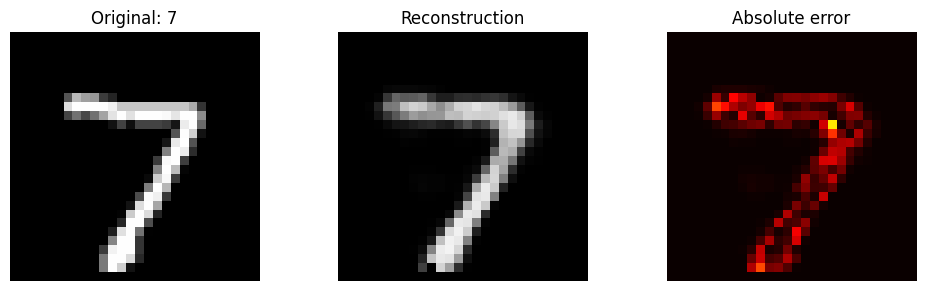

In [18]:
# Select one unseen image from the test dataset.
image, label = test_dataset[0]

model.eval()

with torch.no_grad():
    # Flatten the image for the fully connected network.
    reconstructed = model(image.view(1, 784))

# Restore the original image dimensions.
reconstructed = reconstructed.view(28, 28)

# Calculate absolute pixel-wise reconstruction error.
error_map = (image.squeeze() - reconstructed).abs()

fig, axes = plt.subplots(1, 3, figsize=(10, 3))

axes[0].imshow(image.squeeze(), cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"Original: {label}")

axes[1].imshow(reconstructed, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Reconstruction")

axes[2].imshow(error_map, cmap="hot", vmin=0, vmax=1)
axes[2].set_title("Absolute error")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

**From deterministic compression to probabilistic generation**

We will replace the autoencoder's fixed latent vector with a Gaussian distribution parameterized by a mean and log variance. We will sample from this distribution and train the model using reconstruction loss plus KL-divergence regularization.

**Design:** input dimension 784, hidden dimensions 256 and 64, and latent dimension 16.

**Expected outcome:** the model should reconstruct digits and learn a latent space from which we can sample new digit-like images

In [19]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class VAE(nn.Module):
    def __init__(self, input_dim=784, latent_dim=16):
        super().__init__()

        # Encoder: compress the input image.
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU()
        )

        # Predict the mean and log variance of q(z | x).
        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)

        # Decoder: reconstruct an image from z.
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, input_dim),
            nn.Sigmoid()
        )

    def encode(self, x):
        hidden = self.encoder(x)
        mu = self.fc_mu(hidden)
        logvar = self.fc_logvar(hidden)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        # Convert log variance to standard deviation.
        std = torch.exp(0.5 * logvar)

        # Sample random noise from a standard normal distribution.
        eps = torch.randn_like(std)

        # Keep the sampling operation differentiable with respect to mu and std.
        return mu + std * eps

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstruction = self.decode(z)

        return reconstruction, mu, logvar

In [20]:
def vae_loss(reconstruction, x, mu, logvar):
    # Sum pixel-wise binary cross-entropy for each image.
    reconstruction_loss = F.binary_cross_entropy(
        reconstruction,
        x,
        reduction="sum"
    )

    # KL divergence from N(mu, sigma^2) to N(0, I).
    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    total_loss = reconstruction_loss + kl_loss

    return total_loss, reconstruction_loss, kl_loss

In [21]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

vae = VAE().to(device)
optimizer = torch.optim.Adam(vae.parameters(), lr=0.001)

epochs = 5

for epoch in range(epochs):
    vae.train()

    total_loss = 0
    total_recon = 0
    total_kl = 0

    for images, _ in train_loader:
        images = images.view(images.size(0), 784).to(device)

        optimizer.zero_grad()

        reconstruction, mu, logvar = vae(images)

        loss, recon_loss, kl_loss = vae_loss(
            reconstruction, images, mu, logvar
        )

        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        total_recon += recon_loss.item()
        total_kl += kl_loss.item()

    n = len(train_dataset)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Total: {total_loss / n:.4f} | "
        f"Reconstruction: {total_recon / n:.4f} | "
        f"KL: {total_kl / n:.4f}"
    )

Epoch 1/5 | Total: 190.9600 | Reconstruction: 183.9698 | KL: 6.9902
Epoch 2/5 | Total: 140.8775 | Reconstruction: 126.8248 | KL: 14.0527
Epoch 3/5 | Total: 126.7617 | Reconstruction: 110.5493 | KL: 16.2124
Epoch 4/5 | Total: 120.0927 | Reconstruction: 102.8834 | KL: 17.2094
Epoch 5/5 | Total: 116.5738 | Reconstruction: 98.8866 | KL: 17.6871


**Unconditional generation.** We sample \(z\sim\mathcal N(0,I)\) and decode it without supplying an input image. This tests whether the learned latent space supports generation from the prior.

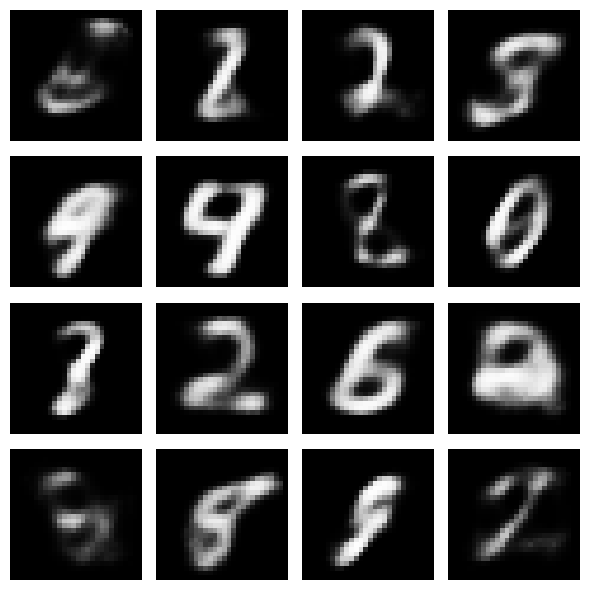

In [22]:
vae.eval()

with torch.no_grad():
    # Sample 16 latent vectors from the standard normal prior.
    z = torch.randn(16, 16, device=device)

    # Decode them into images.
    generated = vae.decode(z).cpu().view(-1, 28, 28)

fig, axes = plt.subplots(4, 4, figsize=(6, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(generated[i], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")

plt.tight_layout()
plt.show()

**Evaluating a Variational Autoencoder**
**Objective:** evaluate reconstruction performance on the MNIST test set and compare it with unconditional generation.

**Hypothesis:** a trained VAE should reconstruct recognizable digits from unseen images, while samples generated from random latent vectors may differ in sharpness and quality.

**Evaluation:** calculate mean squared reconstruction error and visualize original images alongside reconstructions. Use the results to identify limitations before changing the model.

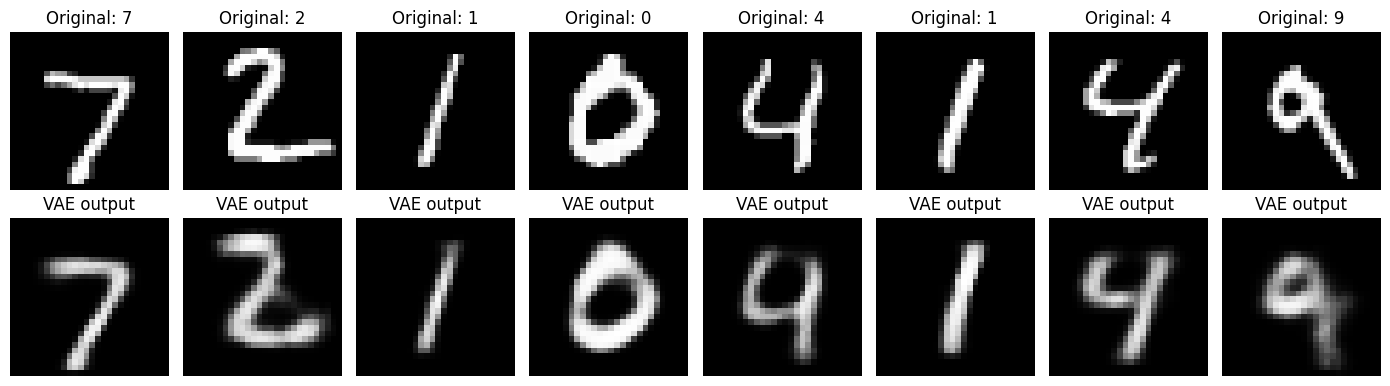

In [23]:
# Put the model in evaluation mode.
vae.eval()

# Get a batch of unseen test images.
images, labels = next(iter(test_loader))
images = images[:8].to(device)

# Reconstruct the images without computing gradients.
with torch.no_grad():
    reconstruction, mu, logvar = vae(images.view(-1, 784))

reconstruction = reconstruction.view(-1, 28, 28).cpu()
original = images.view(-1, 28, 28).cpu()

# Compare original and reconstructed images.
fig, axes = plt.subplots(2, 8, figsize=(14, 4))

for i in range(8):
    axes[0, i].imshow(original[i], cmap="gray", vmin=0, vmax=1)
    axes[0, i].set_title(f"Original: {labels[i].item()}")

    axes[1, i].imshow(
        reconstruction[i], cmap="gray", vmin=0, vmax=1
    )
    axes[1, i].set_title("VAE output")

    axes[0, i].axis("off")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

**Latent Interpolation**
Objective: investigate how the VAE decoder maps intermediate latent vectors to images.

Hypothesis: moving smoothly between two encoded images may produce a sequence of gradual visual transitions.

Method: encode two test images, take their posterior mean vectors, interpolate between those vectors, and decode the intermediate points.

Important: we use the posterior means to make the endpoints deterministic. Intermediate images need not represent valid digits, and smooth interpolation is not guaranteed.

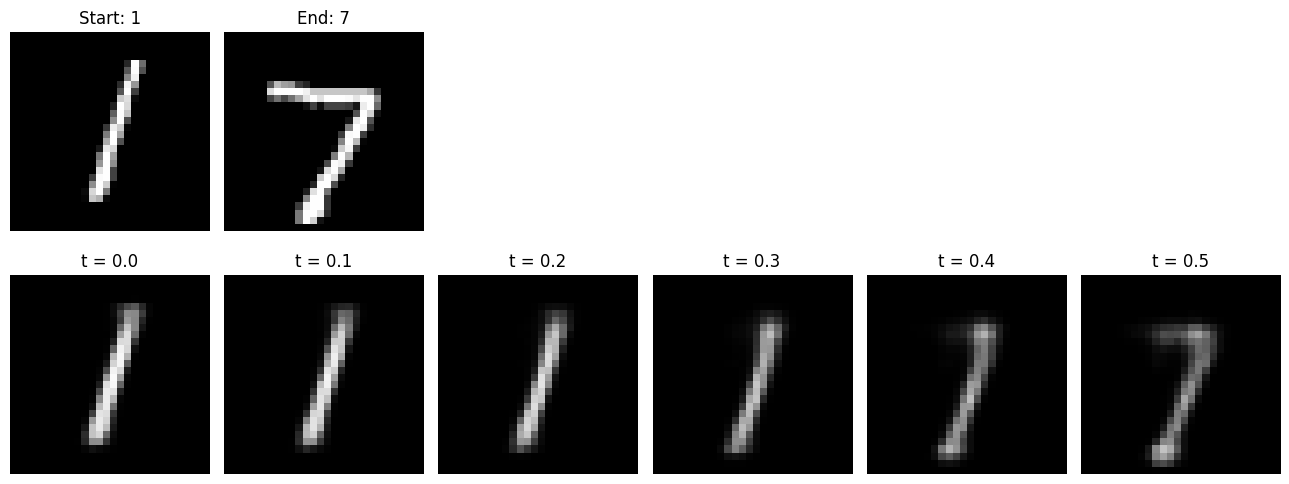

In [24]:
import torch
import matplotlib.pyplot as plt

# Put the trained VAE into evaluation mode.
vae.eval()

# Find one example of digit 1 and one example of digit 7.
digit_a = next(
    (img, label)
    for img, label in test_dataset
    if label == 1
)

digit_b = next(
    (img, label)
    for img, label in test_dataset
    if label == 7
)

image_a, label_a = digit_a
image_b, label_b = digit_b

with torch.no_grad():
    # Flatten both images and move them to the model's device.
    x_a = image_a.view(1, 784).to(device)
    x_b = image_b.view(1, 784).to(device)

    # Encode images and retrieve their latent means.
    mu_a, logvar_a = vae.encode(x_a)
    mu_b, logvar_b = vae.encode(x_b)

    # Generate 11 points, including both endpoints.
    alphas = torch.linspace(0, 1, 11, device=device)

    latent_path = torch.cat(
        [(1 - t) * mu_a + t * mu_b for t in alphas],
        dim=0
    )

    # Decode all intermediate latent vectors.
    generated = vae.decode(latent_path).cpu().view(-1, 28, 28)

# Display the original images and interpolation sequence.
fig, axes = plt.subplots(2, 6, figsize=(13, 5))

axes[0, 0].imshow(image_a.squeeze(), cmap="gray")
axes[0, 0].set_title(f"Start: {label_a}")

axes[0, 1].imshow(image_b.squeeze(), cmap="gray")
axes[0, 1].set_title(f"End: {label_b}")

for ax in axes[0, 2:]:
    ax.axis("off")

for i, ax in enumerate(axes[1]):
    ax.imshow(generated[i], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"t = {alphas[i].item():.1f}")
    ax.axis("off")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

**Two-Dimensional Latent Projection**

We encode test images and plot the first two components of each posterior mean. Points are coloured by their true digit labels so we can investigate whether similar digits occupy nearby regions.

Limitation: this is only a projection of a 16-dimensional representation. The first two coordinates may not preserve all relevant structure, and overlapping points do not necessarily imply that the full latent representations are similar.

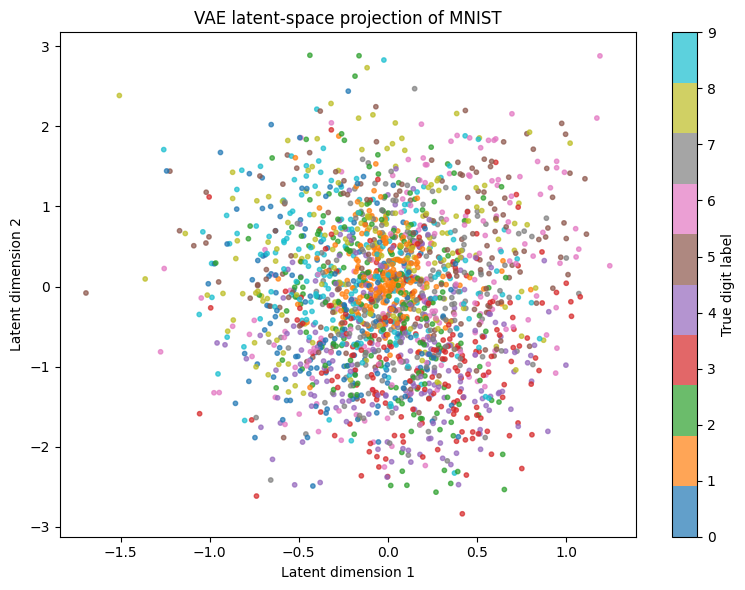

In [25]:
import numpy as np
import matplotlib.pyplot as plt

vae.eval()

latent_points = []
digit_labels = []

# Use a subset first to keep the visualization quick.
for image, label in test_dataset:
    with torch.no_grad():
        x = image.view(1, 784).to(device)
        mu, _ = vae.encode(x)

    # Save the first two latent mean coordinates.
    latent_points.append(mu[0, :2].cpu().numpy())
    digit_labels.append(label)

    if len(latent_points) >= 2000:
        break

latent_points = np.array(latent_points)
digit_labels = np.array(digit_labels)

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    latent_points[:, 0],
    latent_points[:, 1],
    c=digit_labels,
    cmap="tab10",
    s=10,
    alpha=0.7
)

plt.xlabel("Latent dimension 1")
plt.ylabel("Latent dimension 2")
plt.title("VAE latent-space projection of MNIST")
plt.colorbar(scatter, label="True digit label")
plt.tight_layout()
plt.show()

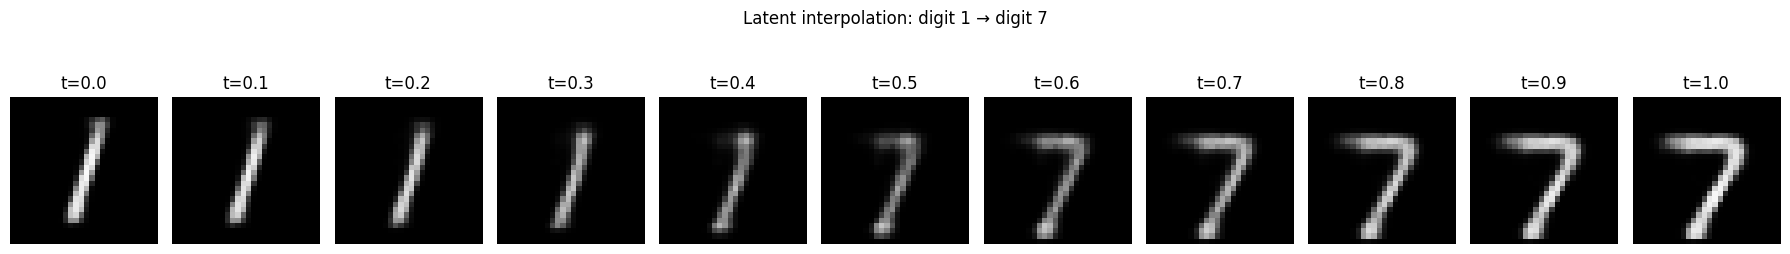

In [26]:
# Experiment 6A: Display the complete latent interpolation path.
# The latent vectors were generated in the previous cell.

fig, axes = plt.subplots(1, len(alphas), figsize=(18, 3))

for i, ax in enumerate(axes):
    ax.imshow(generated[i], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"t={alphas[i].item():.1f}")
    ax.axis("off")

plt.suptitle("Latent interpolation: digit 1 → digit 7")
plt.tight_layout()
plt.show()

**Effect of Latent Dimension**
Objective: investigate how latent-space size affects VAE reconstruction quality.

Hypothesis: a smaller latent dimension may limit the information retained about an image, while a larger latent dimension may improve reconstruction. However, the result also depends on training, regularization and model capacity.

Method: train otherwise identical VAEs with latent dimensions of 2, 16 and 32, then compare their test-set reconstruction MSE and KL divergence.

Controlled variables: architecture apart from latent size, optimizer, learning rate, batch size, training duration and data split.

Limitation: a single run per setting provides preliminary evidence, not a definitive conclusion. Random initialization and sampling introduce variation.

In [27]:
# Experiment 7A: Configure the latent-dimension comparison.
# Keep the original trained VAE unchanged.

latent_dimensions = [2, 16, 32]
experiment_epochs = 5

print("Latent dimensions to compare:", latent_dimensions)
print("Training epochs per model:", experiment_epochs)

Latent dimensions to compare: [2, 16, 32]
Training epochs per model: 5


**Training VAEs with Different Latent Dimensions**

We will train three VAEs with latent dimensions of 2, 16 and 32. Each model will use the same MNIST training data, architecture pattern, optimizer and number of epochs.

We will evaluate them on the same held-out test dataset using reconstruction MSE and KL divergence. This helps us investigate how latent capacity affects reconstruction and regularization.

In [28]:
# Experiment 7B: Train separate VAEs for a fair comparison.

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

results = {}

for latent_dim in latent_dimensions:
    print(f"\nTraining VAE with latent dimension = {latent_dim}")

    # Create a fresh model; do not overwrite your original vae.
    experiment_vae = VAE(latent_dim=latent_dim).to(device)

    experiment_optimizer = torch.optim.Adam(
        experiment_vae.parameters(),
        lr=0.001
    )

    # Train the model.
    for epoch in range(experiment_epochs):
        experiment_vae.train()
        total_epoch_loss = 0.0

        for images, _ in train_loader:
            images = images.view(images.size(0), 784).to(device)

            experiment_optimizer.zero_grad()

            reconstruction, mu, logvar = experiment_vae(images)

            loss, recon_loss, kl_loss = vae_loss(
                reconstruction, images, mu, logvar
            )

            loss.backward()
            experiment_optimizer.step()

            total_epoch_loss += loss.item()

        print(
            f"Epoch {epoch + 1}/{experiment_epochs} | "
            f"Average loss: "
            f"{total_epoch_loss / len(train_dataset):.4f}"
        )

    # Evaluate on unseen test images.
    experiment_vae.eval()

    squared_error_sum = 0.0
    pixel_count = 0
    kl_sum = 0.0
    image_count = 0

    with torch.no_grad():
        for images, _ in test_loader:
            images = images.view(images.size(0), 784).to(device)

            reconstruction, mu, logvar = experiment_vae(images)

            squared_error_sum += (
                (reconstruction - images) ** 2
            ).sum().item()

            pixel_count += images.numel()

            # KL divergence summed over latent dimensions and images.
            batch_kl = -0.5 * (
                1 + logvar - mu.pow(2) - logvar.exp()
            ).sum()

            kl_sum += batch_kl.item()
            image_count += images.size(0)

    results[latent_dim] = {
        "test_mse": squared_error_sum / pixel_count,
        "kl_per_image": kl_sum / image_count,
        "model": experiment_vae
    }

    print(f"Test MSE: {results[latent_dim]['test_mse']:.6f}")
    print(f"KL per image: {results[latent_dim]['kl_per_image']:.4f}")

print("\nExperiment complete.")


Training VAE with latent dimension = 2
Epoch 1/5 | Average loss: 197.7268
Epoch 2/5 | Average loss: 167.9392
Epoch 3/5 | Average loss: 162.2879
Epoch 4/5 | Average loss: 157.7007
Epoch 5/5 | Average loss: 154.9951
Test MSE: 0.043513
KL per image: 5.5156

Training VAE with latent dimension = 16
Epoch 1/5 | Average loss: 194.9981
Epoch 2/5 | Average loss: 143.1277
Epoch 3/5 | Average loss: 128.2725
Epoch 4/5 | Average loss: 120.9913
Epoch 5/5 | Average loss: 117.0461
Test MSE: 0.020569
KL per image: 17.5948

Training VAE with latent dimension = 32
Epoch 1/5 | Average loss: 197.0178
Epoch 2/5 | Average loss: 147.5830
Epoch 3/5 | Average loss: 131.3046
Epoch 4/5 | Average loss: 123.3426
Epoch 5/5 | Average loss: 118.4849
Test MSE: 0.021456
KL per image: 16.8429

Experiment complete.


**Analysis:** Test MSE measures average squared pixel error, while KL divergence measures how far the learned latent distributions depart from the standard normal prior. We should consider both metrics rather than selecting a model using only one

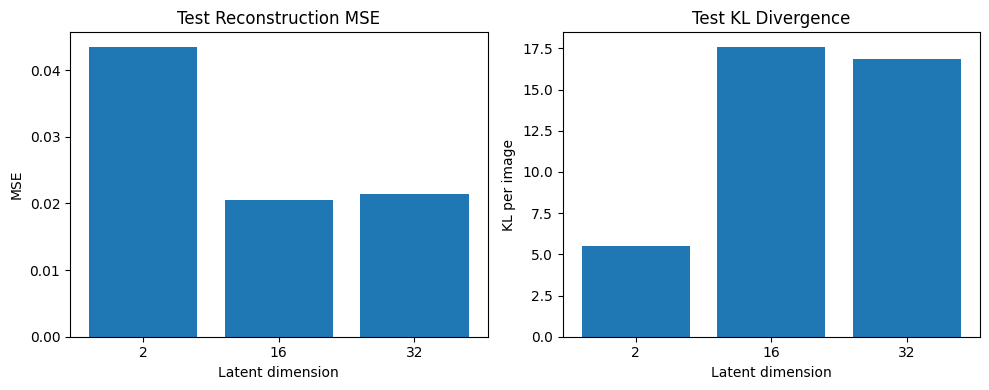

In [29]:
# Experiment 7C: Visualize the metric comparison.

dims = list(results.keys())
test_mses = [results[d]["test_mse"] for d in dims]
kl_values = [results[d]["kl_per_image"] for d in dims]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar([str(d) for d in dims], test_mses)
axes[0].set_title("Test Reconstruction MSE")
axes[0].set_xlabel("Latent dimension")
axes[0].set_ylabel("MSE")

axes[1].bar([str(d) for d in dims], kl_values)
axes[1].set_title("Test KL Divergence")
axes[1].set_xlabel("Latent dimension")
axes[1].set_ylabel("KL per image")

plt.tight_layout()
plt.show()

**Reconstruction–Regularization Trade-off**

Objective: investigate how the KL weight influences reconstruction quality and latent-space regularization.

Method: train models with \(\beta=0.5,\ 1.0,\ 2.0\), using a fixed latent dimension of 16.

Hypothesis: stronger regularization may encourage a latent distribution closer to the prior, but can reduce reconstruction quality. The actual outcome must be measured.

Controlled variables: latent dimension, architecture, dataset, optimizer, learning rate and epochs.

Evaluation: record test reconstruction MSE, test KL divergence and generated samples.

In [30]:
# Experiment 7D: Compare different KL weights.

beta_values = [0.5, 1.0, 2.0]
beta_results = {}

for beta in beta_values:
    print(f"\nTraining with beta = {beta}")

    beta_vae = VAE(latent_dim=16).to(device)
    beta_optimizer = torch.optim.Adam(
        beta_vae.parameters(), lr=0.001
    )

    for epoch in range(5):
        beta_vae.train()
        epoch_loss = 0.0

        for images, _ in train_loader:
            images = images.view(images.size(0), 784).to(device)

            beta_optimizer.zero_grad()
            reconstruction, mu, logvar = beta_vae(images)

            # Separate reconstruction and KL terms.
            recon_loss = F.binary_cross_entropy(
                reconstruction, images, reduction="sum"
            )

            kl_loss = -0.5 * torch.sum(
                1 + logvar - mu.pow(2) - logvar.exp()
            )

            # Beta controls the strength of regularization.
            loss = recon_loss + beta * kl_loss

            loss.backward()
            beta_optimizer.step()

            epoch_loss += loss.item()

        print(
            f"Epoch {epoch + 1}/5 | "
            f"Average beta-VAE loss: "
            f"{epoch_loss / len(train_dataset):.4f}"
        )

    # Evaluate on the same test dataset.
    beta_vae.eval()
    squared_error = 0.0
    pixel_count = 0
    kl_total = 0.0
    image_count = 0

    with torch.no_grad():
        for images, _ in test_loader:
            images = images.view(images.size(0), 784).to(device)
            reconstruction, mu, logvar = beta_vae(images)

            squared_error += (
                (reconstruction - images) ** 2
            ).sum().item()
            pixel_count += images.numel()

            kl_total += (
                -0.5 * (
                    1 + logvar - mu.pow(2) - logvar.exp()
                ).sum().item()
            )
            image_count += images.size(0)

    beta_results[beta] = {
        "test_mse": squared_error / pixel_count,
        "kl_per_image": kl_total / image_count,
        "model": beta_vae
    }

    print(f"Test MSE: {beta_results[beta]['test_mse']:.6f}")
    print(f"KL per image: {beta_results[beta]['kl_per_image']:.4f}")


Training with beta = 0.5
Epoch 1/5 | Average beta-VAE loss: 185.3381
Epoch 2/5 | Average beta-VAE loss: 130.8587
Epoch 3/5 | Average beta-VAE loss: 117.6720
Epoch 4/5 | Average beta-VAE loss: 110.1797
Epoch 5/5 | Average beta-VAE loss: 105.4243
Test MSE: 0.017439
KL per image: 25.8878

Training with beta = 1.0
Epoch 1/5 | Average beta-VAE loss: 192.7581
Epoch 2/5 | Average beta-VAE loss: 141.0531
Epoch 3/5 | Average beta-VAE loss: 127.5909
Epoch 4/5 | Average beta-VAE loss: 120.6494
Epoch 5/5 | Average beta-VAE loss: 116.6283
Test MSE: 0.020429
KL per image: 17.4394

Training with beta = 2.0
Epoch 1/5 | Average beta-VAE loss: 201.9076
Epoch 2/5 | Average beta-VAE loss: 159.3934
Epoch 3/5 | Average beta-VAE loss: 143.8906
Epoch 4/5 | Average beta-VAE loss: 137.3397
Epoch 5/5 | Average beta-VAE loss: 133.5970
Test MSE: 0.025097
KL per image: 11.8934


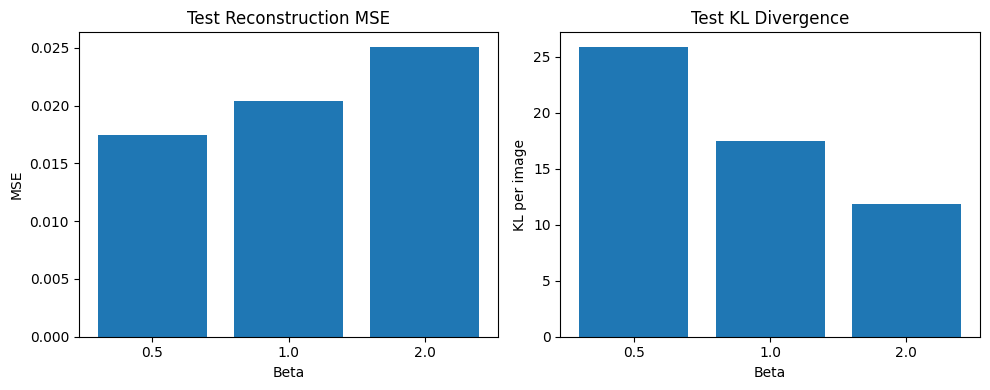

In [31]:
# Compare test metrics across beta values.

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(
    [str(b) for b in beta_values],
    [beta_results[b]["test_mse"] for b in beta_values]
)
axes[0].set_title("Test Reconstruction MSE")
axes[0].set_xlabel("Beta")
axes[0].set_ylabel("MSE")

axes[1].bar(
    [str(b) for b in beta_values],
    [beta_results[b]["kl_per_image"] for b in beta_values]
)
axes[1].set_title("Test KL Divergence")
axes[1].set_xlabel("Beta")
axes[1].set_ylabel("KL per image")

plt.tight_layout()
plt.show()

### Experiment 7D: Effect of KL-Divergence Weight

**Objective:** Investigate how the beta parameter affects the reconstruction–regularization trade-off in a Variational Autoencoder.

**Experimental setup:** Three VAEs were trained for five epochs with a latent dimension of 16, using beta values of 0.5, 1.0 and 2.0.

**Results:**

| Beta | Test MSE | Test KL divergence per image |
|---:|---:|---:|
| 0.5 | 0.017439 | 25.8878 |
| 1.0 | 0.020429 | 17.4394 |
| 2.0 | 0.025097 | 11.8934 |

**Interpretation:** The beta = 0.5 model achieved the lowest test reconstruction MSE, while beta = 2.0 produced the lowest KL divergence. This is consistent with a trade-off between reconstruction accuracy and latent-distribution regularization.

**Limitations:** Each configuration was trained for five epochs in one run. Random initialization and stochastic sampling may affect the results. Repeated runs and additional evaluation would be needed to establish robust conclusions.

**Conclusion:** The beta parameter influences the balance between reconstruction quality and latent-space regularization. Its best value depends on the intended use of the generative model.
